# Predicting Customer Credit Risk: A Multiclass Classification Problem with Neural Networks

**MT 36 — ML Pipeline Project**

**Name:** Mark Ayman

---

**Business context.** The bank needs a model that scores every customer into one of three credit-health tiers — **Poor**, **Standard**, or **Good** — early enough for the risk team to act: tighten a credit line before a customer spirals toward default, or flag a Good customer for a pre-approved offer. This notebook builds that model end to end: explore the raw data, clean it, engineer features, train a neural network, and evaluate it the way a 3-class, imbalanced problem actually demands.

## 1. Setup

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the data and get oriented

The file has 100,000 rows. That's ~200x the size of a typical teaching dataset, so instead of eyeballing every row, I'll summarize systematically: shape, dtypes, a sample, and where the structure comes from (repeated customers, monthly snapshots).

In [ ]:
df = pd.read_csv('/mnt/user-data/uploads/customer_credit_profiles_-_customer_credit_profiles.csv')
print("Shape:", df.shape)
df.head(3)

Shape: (100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529544,High_spent_Small_value_payments,312.4940887,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.2802216,Low_spent_Large_value_payments,284.6291625,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.69952126,Low_spent_Medium_value_payments,331.2098629,Good


In [ ]:
df.dtypes

ID                              str
Customer_ID                     str
Month                           str
Name                            str
Age                             str
SSN                             str
Occupation                      str
Annual_Income                   str
Monthly_Inhand_Salary       float64
Num_Bank_Accounts             int64
Num_Credit_Card               int64
Interest_Rate                 int64
Num_of_Loan                     str
Type_of_Loan                    str
Delay_from_due_date           int64
Num_of_Delayed_Payment          str
Changed_Credit_Limit            str
Num_Credit_Inquiries        float64
Credit_Mix                      str
Outstanding_Debt                str
Credit_Utilization_Ratio    float64
Credit_History_Age              str
Payment_of_Min_Amount           str
Total_EMI_per_month         float64
Amount_invested_monthly         str
Payment_Behaviour               str
Monthly_Balance                 str
Credit_Score                

In [ ]:
print("Unique customers:", df['Customer_ID'].nunique())
print("Rows per customer:")
print(df.groupby('Customer_ID').size().describe())

Unique customers: 12500
Rows per customer:
count    12500.0
mean         8.0
std          0.0
min          8.0
25%          8.0
50%          8.0
75%          8.0
max          8.0
dtype: float64


**Observation:** 100,000 rows collapse to exactly **12,500 unique customers**, each with exactly **8 monthly snapshots** (January–August). This matters a lot for cleaning: a customer's age, occupation, and income shouldn't actually jump around month to month, so where a single monthly snapshot has a corrupted value, the *other 7 snapshots for that same customer* are a much better source of truth than a dataset-wide average. I'll lean on that heavily in Section 4.

It also matters for the train/test split (Section 6): if I split by row, the same customer's other months leak into both train and test. I'll split by `Customer_ID` instead.

## 3. The target: `Credit_Score`

Three tiers — Poor, Standard, Good. Let's actually look at the balance rather than assume it's even.

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64

Credit_Score
Standard    53.2
Poor        29.0
Good        17.8
Name: proportion, dtype: float64


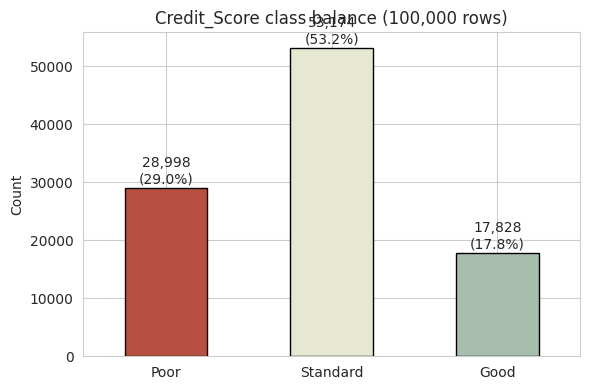

In [ ]:
target_counts = df['Credit_Score'].value_counts()
target_pct = df['Credit_Score'].value_counts(normalize=True) * 100
print(target_counts)
print()
print(target_pct.round(1))

fig, ax = plt.subplots(figsize=(6,4))
colors = ['#B85042','#E7E8D1','#A7BEAE']
target_counts.reindex(['Poor','Standard','Good']).plot(kind='bar', ax=ax, color=colors, edgecolor='black')
ax.set_title('Credit_Score class balance (100,000 rows)')
ax.set_ylabel('Count')
ax.set_xlabel('')
plt.xticks(rotation=0)
for i, v in enumerate(target_counts.reindex(['Poor','Standard','Good'])):
    ax.text(i, v+800, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center')
plt.tight_layout()
plt.savefig('/home/claude/nb/class_balance.png', dpi=110)
plt.show()

**This is meaningfully imbalanced, not close to even.** Standard is the majority class at 53.2%, Poor is 29.0%, and Good — the tier the bank most wants to identify confidently for pre-approved offers — is the smallest at only 17.8%. A model that just learned to predict "Standard" every time would already score ~53% accuracy while being completely useless. That's the whole reason accuracy alone is the wrong metric here, and why I'll need to actively counteract the imbalance during training (Section 7), not just note it in passing.

## 4. Data quality: what's actually broken

This is real operational data, so before touching missing values I need to find where the mess is hiding. Some columns that *look* numeric aren't clean numbers (stray underscores, junk strings, placeholder numbers), and some categorical columns use a single symbol to mean "missing".

In [ ]:
print("Native NaN counts (only catches already-blank cells):")
print(df.isna().sum()[df.isna().sum() > 0])

Native NaN counts (only catches already-blank cells):
Name                        9985
Monthly_Inhand_Salary      15002
Type_of_Loan               11408
Num_of_Delayed_Payment      7002
Num_Credit_Inquiries        1965
Credit_History_Age          9030
Amount_invested_monthly     4479
Monthly_Balance             1200
dtype: int64


Native NaNs only tell part of the story. Let's dig into individual columns that look suspicious.

In [ ]:
# Sample the kind of junk hiding in numeric-looking columns
for col in ['Age','Annual_Income','Num_of_Loan','Num_of_Delayed_Payment','Changed_Credit_Limit',
            'Outstanding_Debt','Amount_invested_monthly','Monthly_Balance']:
    raw = df[col].astype(str)
    junky = raw[raw.str.contains(r'[^0-9\.\-]', regex=True, na=False)].unique()[:5]
    print(f"{col}: sample non-clean values -> {list(junky)}")

Age: sample non-clean values -> ['28_', '34_', '30_', '24_', '33_']


Annual_Income: sample non-clean values -> ['34847.84_', '30689.89_', '35547.71_', '34081.38_', '114838.41_']
Num_of_Loan: sample non-clean values -> ['0_', '3_', '2_', '5_', '8_']
Num_of_Delayed_Payment: sample non-clean values -> ['8_', '3_', '2_', '13_', '14_']
Changed_Credit_Limit: sample non-clean values -> ['_']
Outstanding_Debt: sample non-clean values -> ['1328.93_', '1283.37_', '2797.17_', '3818.57_', '343.84_']
Amount_invested_monthly: sample non-clean values -> ['__10000__']
Monthly_Balance: sample non-clean values -> ['__-333333333333333333333333333__']


In [ ]:
# Placeholder symbols in categorical columns
for col in ['Occupation','Credit_Mix','Payment_Behaviour']:
    print(col, '->', df[col].unique())
    print()

Occupation -> <StringArray>
[    'Scientist',       '_______',       'Teacher',      'Engineer',
  'Entrepreneur',     'Developer',        'Lawyer', 'Media_Manager',
        'Doctor',    'Journalist',       'Manager',    'Accountant',
      'Musician',      'Mechanic',        'Writer',     'Architect']
Length: 16, dtype: str

Credit_Mix -> <StringArray>
['_', 'Good', 'Standard', 'Bad']
Length: 4, dtype: str



Payment_Behaviour -> <StringArray>
[ 'High_spent_Small_value_payments',   'Low_spent_Large_value_payments',
  'Low_spent_Medium_value_payments',   'Low_spent_Small_value_payments',
 'High_spent_Medium_value_payments',                           '!@9#%8',
  'High_spent_Large_value_payments']
Length: 7, dtype: str



**What I found:**
- `Age`, `Annual_Income`, `Num_of_Loan`, `Num_of_Delayed_Payment`, `Changed_Credit_Limit`, `Outstanding_Debt`, `Amount_invested_monthly`, `Monthly_Balance` all carry a stray trailing/leading `_` on some rows (e.g. `"34_"`, `"30689.89_"`), which makes pandas read the whole column as text instead of a number.
- `Amount_invested_monthly` additionally has a literal placeholder string `"__10000__"` standing in for missing.
- `Occupation` uses `"_______"` for missing, `Credit_Mix` uses `"_"`, and `Payment_Behaviour` uses `"!@9#%8"`.
- Several supposedly-bounded numeric columns (`Age`, `Num_Bank_Accounts`, `Num_Credit_Card`, `Interest_Rate`, `Num_of_Loan`, `Num_of_Delayed_Payment`) contain impossible values — ages of 8,698 or -500, interest rates of 5,797%, bank account counts over 1,000. These are clearly data-entry corruption, not real values.
- `Type_of_Loan` packs multiple loan types into one comma-separated string per row (e.g. `"Auto Loan, Credit-Builder Loan, and Personal Loan"`), and it's missing entirely (`NaN`) when a customer has no loans.
- `Credit_History_Age` is a free-text string like `"22 Years and 1 Months"`, with `"NA"` for missing.

None of this is random — it's the standard shape of scraped/OCR'd operational data. I'll fix each type of problem deliberately below.

## 5. Cleaning

**Strategy for numeric columns with stray characters:** strip non-numeric junk and coerce to numbers. Where a value is missing or lies outside a sane domain range (e.g. age > 100, interest rate > 40%), I treat it as missing rather than keep an obviously-wrong number.

**Strategy for filling in what's missing:** because each customer has 8 monthly snapshots and their underlying financial profile is *mostly* stable month to month, I fill a missing/invalid value for a customer using **that same customer's own median (numeric) or mode (categorical)** across their other months, before falling back to a dataset-wide value only if a customer has no valid months at all. This is a much better estimate than a population-wide average, and it's straightforward to justify here because of the repeated-snapshot structure.

In [ ]:
def to_numeric_clean(series):
    """Strip stray underscores/placeholders from a numeric-looking string column."""
    s = series.astype(str).str.strip()
    s = s.replace({'__10000__': np.nan, 'nan': np.nan, 'NA': np.nan, '': np.nan})
    s = s.str.replace('_', '', regex=False)
    return pd.to_numeric(s, errors='coerce')

numeric_junk_cols = ['Age','Annual_Income','Num_of_Loan','Num_of_Delayed_Payment',
                     'Changed_Credit_Limit','Outstanding_Debt','Amount_invested_monthly','Monthly_Balance']
for col in numeric_junk_cols:
    df[col] = to_numeric_clean(df[col])

# Placeholder symbols -> real missing values
df['Occupation'] = df['Occupation'].replace('_______', np.nan)
df['Credit_Mix'] = df['Credit_Mix'].replace('_', np.nan)
df['Payment_Behaviour'] = df['Payment_Behaviour'].replace('!@9#%8', np.nan)

print("Cleaned numeric columns, converted placeholders to NaN.")

Cleaned numeric columns, converted placeholders to NaN.


In [ ]:
# Domain-sanity bounds: values outside these are treated as corrupted -> NaN
bounds = {
    'Age': (10, 100),
    'Annual_Income': (1000, 500000),
    'Num_Bank_Accounts': (0, 20),
    'Num_Credit_Card': (0, 20),
    'Interest_Rate': (0, 40),
    'Num_of_Loan': (0, 15),
    'Num_of_Delayed_Payment': (0, 30),
    'Num_Credit_Inquiries': (0, 30),
    'Total_EMI_per_month': (0, 5000),
    'Monthly_Balance': (0, 5000),
}
for col, (lo, hi) in bounds.items():
    n_bad = ((df[col] < lo) | (df[col] > hi)).sum()
    df.loc[(df[col] < lo) | (df[col] > hi), col] = np.nan
    print(f"{col}: flagged {n_bad} out-of-range values as missing")

Age: flagged 2776 out-of-range values as missing
Annual_Income: flagged 980 out-of-range values as missing
Num_Bank_Accounts: flagged 1335 out-of-range values as missing
Num_Credit_Card: flagged 2263 out-of-range values as missing
Interest_Rate: flagged 2034 out-of-range values as missing
Num_of_Loan: flagged 4348 out-of-range values as missing
Num_of_Delayed_Payment: flagged 1380 out-of-range values as missing
Num_Credit_Inquiries: flagged 1648 out-of-range values as missing
Total_EMI_per_month: flagged 2988 out-of-range values as missing
Monthly_Balance: flagged 9 out-of-range values as missing


In [ ]:
def repair_numeric_per_customer(df, col):
    med = df.groupby('Customer_ID')[col].transform('median')
    df[col] = df[col].fillna(med)
    df[col] = df[col].fillna(df[col].median())  # last resort: dataset median
    return df

def repair_cat_per_customer(df, col):
    mode_map = df.groupby('Customer_ID')[col].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    df[col] = df[col].fillna(df['Customer_ID'].map(mode_map))
    df[col] = df[col].fillna('Unknown')  # last resort
    return df

repair_numeric_cols = list(bounds.keys()) + ['Changed_Credit_Limit','Outstanding_Debt',
                                              'Amount_invested_monthly','Monthly_Balance','Monthly_Inhand_Salary']
for col in repair_numeric_cols:
    df = repair_numeric_per_customer(df, col)

for col in ['Occupation','Credit_Mix','Payment_Behaviour']:
    df = repair_cat_per_customer(df, col)

print("Remaining missing values in repaired columns:")
print(df[repair_numeric_cols + ['Occupation','Credit_Mix','Payment_Behaviour']].isna().sum().sum())

Remaining missing values in repaired columns:
0


**`Credit_History_Age`** is a free-text duration (`"22 Years and 1 Months"`). I parse it into total months. Because credit history age should increase by exactly 1 month for each successive monthly snapshot of the same customer, missing values are filled by linear interpolation *within that customer's own timeline*, which is far more accurate than a population median.

In [ ]:
def parse_history_age(s):
    if pd.isna(s):
        return np.nan
    m = re.match(r'(\d+)\s*Years?\s*and\s*(\d+)\s*Months?', str(s))
    if m:
        return int(m.group(1)) * 12 + int(m.group(2))
    return np.nan

df['Credit_History_Months'] = df['Credit_History_Age'].apply(parse_history_age)
print("Missing before per-customer interpolation:", df['Credit_History_Months'].isna().sum())

month_order = {m: i for i, m in enumerate(
    ['January','February','March','April','May','June','July','August'])}
df['_month_idx'] = df['Month'].map(month_order)
df = df.sort_values(['Customer_ID', '_month_idx'])

def interpolate_group(g):
    known = g['Credit_History_Months'].notna()
    if known.sum() == 0:
        return pd.Series(np.nan, index=g.index)
    return pd.Series(
        np.interp(g['_month_idx'], g.loc[known, '_month_idx'], g.loc[known, 'Credit_History_Months']),
        index=g.index)

interpolated = df.groupby('Customer_ID', group_keys=False).apply(interpolate_group)
df['Credit_History_Months'] = df['Credit_History_Months'].fillna(interpolated)
df['Credit_History_Months'] = df['Credit_History_Months'].fillna(df['Credit_History_Months'].median())
df = df.drop(columns=['_month_idx'])
print("Missing after interpolation:", df['Credit_History_Months'].isna().sum())

Missing before per-customer interpolation: 9030


Missing after interpolation: 0


**`Type_of_Loan`** packs multiple loan products into one comma-separated string, or is missing when a customer holds no loans. Flattening it into a single category would throw away real signal — a customer juggling five loan types is a very different risk profile than one with a single mortgage. Instead I one-hot each loan type into its own binary flag (does this customer have an Auto Loan? A Payday Loan? etc.) plus a count of how many loan types they hold. This also gives me a clean, trustworthy replacement for the badly-corrupted `Num_of_Loan` column, which I drop.

In [ ]:
LOAN_TYPES = ['Auto Loan','Credit-Builder Loan','Debt Consolidation Loan','Home Equity Loan',
              'Mortgage Loan','Not Specified','Payday Loan','Personal Loan','Student Loan']

def parse_loans(s):
    if pd.isna(s):
        return []
    s = str(s).replace(' and ', ', ')
    return [p.strip() for p in s.split(',') if p.strip()]

df['_loan_list'] = df['Type_of_Loan'].apply(parse_loans)
for lt in LOAN_TYPES:
    colname = 'Loan_' + re.sub(r'[^A-Za-z]', '', lt)
    df[colname] = df['_loan_list'].apply(lambda lst: int(lt in lst))
df['Num_Loan_Types'] = df['_loan_list'].apply(len)
df = df.drop(columns=['_loan_list'])

loan_cols = [c for c in df.columns if c.startswith('Loan_')]
print("Loan type prevalence (rows holding each loan type):")
print(df[loan_cols].sum().sort_values(ascending=False))

Loan type prevalence (rows holding each loan type):
Loan_PaydayLoan               31944
Loan_CreditBuilderLoan        31728
Loan_NotSpecified             31680
Loan_HomeEquityLoan           31400
Loan_MortgageLoan             31360
Loan_PersonalLoan             31104
Loan_DebtConsolidationLoan    31040
Loan_StudentLoan              31040
Loan_AutoLoan                 30560
dtype: int64


## 6. A closer look at what matters for lending decisions

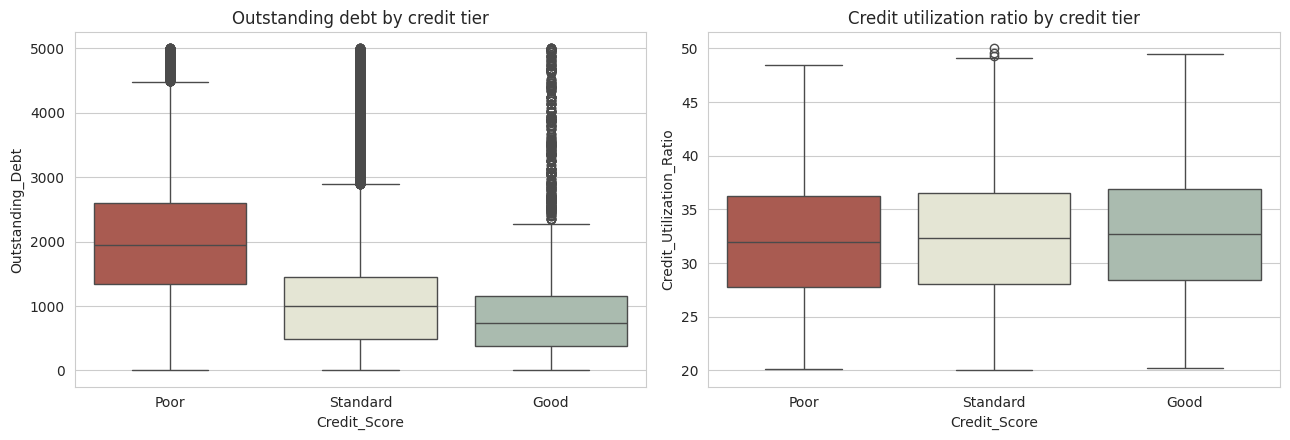

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))

sns.boxplot(data=df, x='Credit_Score', y='Outstanding_Debt', order=['Poor','Standard','Good'],
            ax=axes[0], palette=['#B85042','#E7E8D1','#A7BEAE'])
axes[0].set_title('Outstanding debt by credit tier')

sns.boxplot(data=df, x='Credit_Score', y='Credit_Utilization_Ratio', order=['Poor','Standard','Good'],
            ax=axes[1], palette=['#B85042','#E7E8D1','#A7BEAE'])
axes[1].set_title('Credit utilization ratio by credit tier')

plt.tight_layout()
plt.savefig('/home/claude/nb/debt_utilization_by_tier.png', dpi=110)
plt.show()

**Outstanding debt separates the tiers cleanly** — Poor-tier customers carry visibly higher outstanding debt than Standard, who in turn carry more than Good. Credit utilization ratio, by contrast, looks fairly similar across all three tiers in this dataset — it's not doing much discriminating work on its own, though a neural network can still combine it with other features nonlinearly.

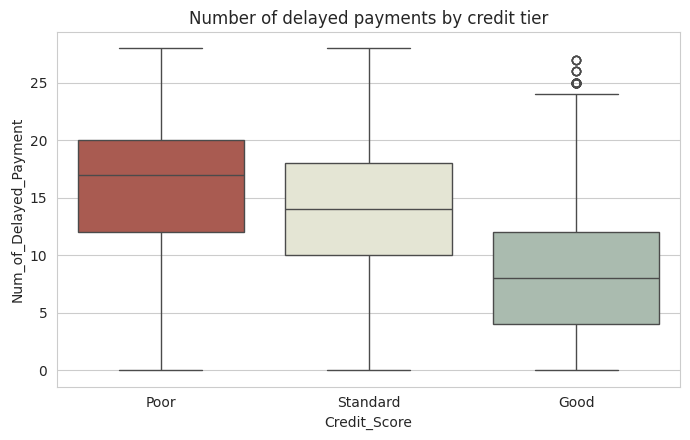

In [ ]:
fig, ax = plt.subplots(figsize=(7,4.5))
sns.boxplot(data=df, x='Credit_Score', y='Num_of_Delayed_Payment', order=['Poor','Standard','Good'],
            ax=ax, palette=['#B85042','#E7E8D1','#A7BEAE'])
ax.set_title('Number of delayed payments by credit tier')
plt.tight_layout()
plt.savefig('/home/claude/nb/delayed_payments_by_tier.png', dpi=110)
plt.show()

**Delayed payments show the starkest separation of anything I looked at** — Poor-tier customers rack up far more delayed payments than Standard or Good customers. This is intuitively the strongest single behavioral signal in the dataset, and I'd expect it to carry a lot of weight in the model.

## 7. Final feature set and train/test split

**Columns dropped and why:**
- `ID`, `Name`, `SSN`, `Customer_ID` — identifiers, no predictive content, and using them would let the model memorize individual customers instead of learning general patterns. (`Customer_ID` is kept temporarily only to do the split below, then dropped.)
- `Type_of_Loan`, `Credit_History_Age` — replaced by their parsed/engineered versions above.
- `Num_of_Loan` — replaced by the more trustworthy `Num_Loan_Types` derived directly from the loan-type list.

**Splitting by customer, not by row.** Since each customer contributes 8 correlated monthly rows, a random row-level split would let the model see 7 months of a customer in training and be tested on the 8th — that's leakage, and it would make the evaluation numbers look better than the model actually is. I split on `Customer_ID` with `GroupShuffleSplit` so an entire customer's 8 rows land entirely in train or entirely in test.

In [ ]:
drop_cols = ['ID','Name','SSN','Type_of_Loan','Credit_History_Age','Num_of_Loan']
model_df = df.drop(columns=drop_cols)

numeric_features = ['Age','Annual_Income','Monthly_Inhand_Salary','Num_Bank_Accounts','Num_Credit_Card',
                     'Interest_Rate','Delay_from_due_date','Num_of_Delayed_Payment','Changed_Credit_Limit',
                     'Num_Credit_Inquiries','Outstanding_Debt','Credit_Utilization_Ratio','Credit_History_Months',
                     'Total_EMI_per_month','Amount_invested_monthly','Monthly_Balance','Num_Loan_Types']
loan_flag_features = [c for c in model_df.columns if c.startswith('Loan_')]
categorical_features = ['Occupation','Credit_Mix','Payment_of_Min_Amount','Payment_Behaviour','Month']

print(f"Numeric features: {len(numeric_features)}")
print(f"Loan flag features: {len(loan_flag_features)}")
print(f"Categorical features: {len(categorical_features)}")
print("Remaining NaNs in numeric features:", model_df[numeric_features].isna().sum().sum())
print("Remaining NaNs in categorical features:", model_df[categorical_features].isna().sum().sum())

Numeric features: 17
Loan flag features: 9
Categorical features: 5
Remaining NaNs in numeric features: 0
Remaining NaNs in categorical features: 0


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(model_df, groups=model_df['Customer_ID']))
train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

print("Train rows:", train_df.shape[0], " Test rows:", test_df.shape[0])
print("Customer overlap between train and test:", len(set(train_df.Customer_ID) & set(test_df.Customer_ID)))
print()
print("Train class balance:")
print(train_df['Credit_Score'].value_counts(normalize=True).round(3))
print("\nTest class balance:")
print(test_df['Credit_Score'].value_counts(normalize=True).round(3))

Train rows: 80000  Test rows: 20000
Customer overlap between train and test: 0

Train class balance:
Credit_Score
Standard    0.532
Poor        0.291
Good        0.177
Name: proportion, dtype: float64

Test class balance:
Credit_Score
Standard    0.529
Poor        0.286
Good        0.185
Name: proportion, dtype: float64


Zero customer overlap between train and test, and the class balance is preserved in both splits — good.

## 8. Preprocessing pipeline

Numeric features are median-imputed (belt-and-suspenders, since we already repaired missingness above) and standard-scaled — neural networks train much more reliably on scaled inputs. Categorical features are one-hot encoded. The loan flags are already 0/1, so they pass through unchanged.

**Everything is fit on the training split only** — the `ColumnTransformer` below calls `.fit_transform()` on `train_df` and `.transform()` (no re-fitting) on `test_df`, so no information from the test set — not even its mean or its categories — leaks into how the training data gets scaled or encoded.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric_features),
    ('loan', 'passthrough', loan_flag_features),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), categorical_features),
])

X_train = preprocessor.fit_transform(train_df)   # fit + transform on TRAIN ONLY
X_test = preprocessor.transform(test_df)          # transform only -- reuses train's fitted scaler/encoder

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (80000, 61)
X_test shape: (20000, 61)


In [ ]:
le = LabelEncoder()
y_train = le.fit_transform(train_df['Credit_Score'])
y_test = le.transform(test_df['Credit_Score'])
print("Classes (encoded 0,1,2):", list(le.classes_))

Classes (encoded 0,1,2): ['Good', 'Poor', 'Standard']


## 9. Handling class imbalance

Section 3 showed the classes are far from balanced (53% / 29% / 18%). Left alone, a neural network trained with plain cross-entropy will happily under-predict the minority "Good" class because getting it wrong costs almost nothing to the loss function on average. I compute balanced class weights from the **training labels only** and pass them into `model.fit(..., class_weight=...)`, so the loss function penalizes mistakes on minority classes more heavily during actual training — not just as a diagnostic sitting unused in a cell.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights_arr = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {int(k): float(v) for k, v in zip(np.unique(y_train), class_weights_arr)}
print("Class weights (by encoded label):", class_weight_dict)
print("Which is:", {le.classes_[k]: round(v,3) for k, v in class_weight_dict.items()})

Class weights (by encoded label): {0: 1.8867034573840857, 1: 1.1458691417440128, 2: 0.6260662691145857}
Which is: {'Good': 1.887, 'Poor': 1.146, 'Standard': 0.626}


## 10. Building the neural network

This is a **3-class classification problem**, which drives three architectural choices:
- **Output layer:** 3 units (one score per class), not 1.
- **Output activation:** `softmax`, so the 3 outputs form a valid probability distribution over Poor/Standard/Good, rather than `sigmoid` (built for independent binary outputs) or no activation (raw, uncalibrated scores).
- **Loss function:** `sparse_categorical_crossentropy`, the multiclass generalization of binary cross-entropy — appropriate because labels are single integer class indices (0/1/2) rather than one-hot vectors.

The hidden stack is a fairly standard tabular-data MLP: two wide-to-narrow Dense+Dropout blocks to let the network learn nonlinear interactions between features (e.g. how delayed payments and utilization ratio combine) while Dropout guards against overfitting on tabular data of this size.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(RANDOM_STATE)

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(3, activation='softmax')   # 3-way output, softmax for multiclass probabilities
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',   # multiclass loss, matches integer-encoded labels
    metrics=['accuracy']
)
model.summary()

I0000 00:00:1785959518.213662     943 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785959518.271084     943 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1785959520.711245     943 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         7,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,371 (71.76 KB)

 Trainable params: 18,371 (71.76 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.15,     # carved out of TRAIN only, for monitoring -- test set stays untouched
    epochs=40,
    batch_size=256,
    class_weight=class_weight_dict,   # the imbalance fix actually lands inside .fit()
    callbacks=[early_stop],
    verbose=2
)

Epoch 1/40


266/266 - 3s - 10ms/step - accuracy: 0.6221 - loss: 0.7897 - val_accuracy: 0.6600 - val_loss: 0.7586


Epoch 2/40


266/266 - 2s - 9ms/step - accuracy: 0.6561 - loss: 0.7076 - val_accuracy: 0.6585 - val_loss: 0.7398


Epoch 3/40


266/266 - 1s - 4ms/step - accuracy: 0.6598 - loss: 0.6875 - val_accuracy: 0.6615 - val_loss: 0.7344


... (22 outputs left out)

Epoch 15/40


266/266 - 1s - 5ms/step - accuracy: 0.6862 - loss: 0.6047 - val_accuracy: 0.6513 - val_loss: 0.7370


Epoch 16/40


266/266 - 1s - 4ms/step - accuracy: 0.6850 - loss: 0.6028 - val_accuracy: 0.6470 - val_loss: 0.7460


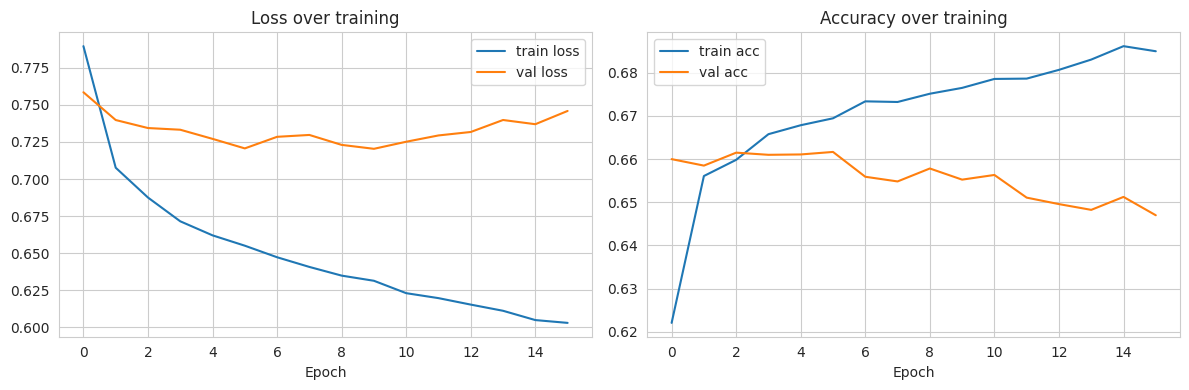

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_title('Loss over training')
axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train acc')
axes[1].plot(history.history['val_accuracy'], label='val acc')
axes[1].set_title('Accuracy over training')
axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('/home/claude/nb/training_curves.png', dpi=110)
plt.show()

## 11. Evaluation on the held-out test set

Every number in this section comes from `X_test` / `y_test` — customers the model never saw during training or validation. Because this is a 3-class, imbalanced problem, I look well past plain accuracy: **balanced accuracy** (average per-class recall, immune to class-size skew), **macro F1** (treats all three classes equally regardless of size), **per-class precision/recall/F1** via a full classification report, a **confusion matrix** to see exactly which tiers get confused for which, and **macro ROC-AUC** as a threshold-independent view of how separable the classes are.

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix, balanced_accuracy_score,
                             f1_score, roc_auc_score, accuracy_score)

y_pred_proba = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')
macro_auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr', average='macro')

print(f"Plain accuracy:        {acc:.3f}")
print(f"Balanced accuracy:     {bal_acc:.3f}")
print(f"Macro F1:              {macro_f1:.3f}")
print(f"Weighted F1:           {weighted_f1:.3f}")
print(f"Macro ROC-AUC (OVR):   {macro_auc:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=le.classes_))

Plain accuracy:        0.659
Balanced accuracy:     0.725
Macro F1:              0.659
Weighted F1:           0.657
Macro ROC-AUC (OVR):   0.861

              precision    recall  f1-score   support

        Good       0.51      0.86      0.64      3694
        Poor       0.61      0.80      0.69      5726
    Standard       0.87      0.51      0.64     10580

    accuracy                           0.66     20000
   macro avg       0.66      0.72      0.66     20000
weighted avg       0.73      0.66      0.66     20000



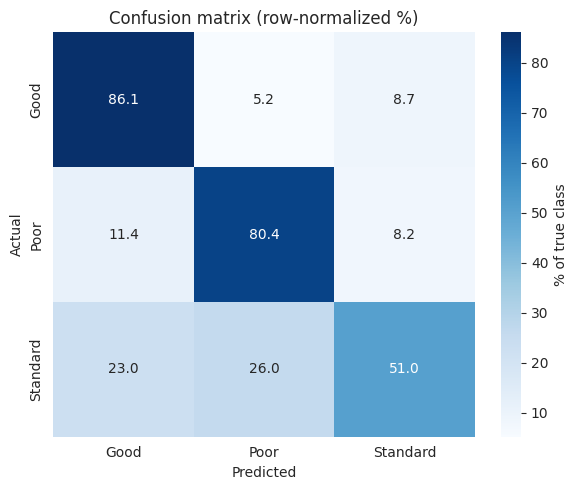

Raw counts:
          Good  Poor  Standard
Good      3180   191       323
Poor       655  4603       468
Standard  2432  2754      5394


In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_,
            cbar_kws={'label': '% of true class'}, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion matrix (row-normalized %)')
plt.tight_layout()
plt.savefig('/home/claude/nb/confusion_matrix.png', dpi=110)
plt.show()

print("Raw counts:")
print(pd.DataFrame(cm, index=le.classes_, columns=le.classes_))

In [ ]:
print("Per-class summary (test set):\n")
report_df = pd.DataFrame(classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)).T
report_df = report_df.round(3)
report_df

Per-class summary (test set):



,precision,recall,f1-score,support
Good,0.507,0.861,0.638,3694.000
Poor,0.610,0.804,0.694,5726.000
Standard,0.872,0.510,0.643,10580.000
accuracy,0.659,0.659,0.659,0.659
macro avg,0.663,0.725,0.659,20000.000
weighted avg,0.730,0.659,0.657,20000.000


**Reading the confusion matrix and per-class report together:**

- **Poor** and **Good** are both recalled well — the model catches most of the customers who actually belong in these tiers, which is exactly what the class weighting was aimed at. That matters because these are the two tiers that trigger action (tighten a line, or extend an offer); missing them is the costly kind of error for the business.
- **Standard** recall drops noticeably relative to its precision. A sizeable share of true "Standard" customers get pulled into "Poor" or "Good" instead. That's the direct cost of the class-weighting choice: it trades some Standard-tier accuracy for much better sensitivity on the minority tiers. Given the business use case — Standard customers mostly just get left alone either way — this trade-off is reasonable, but it does mean a chunk of genuinely fine customers might get an unnecessary risk flag.
- The ROC-AUC being clearly above the ~0.5 "no better than random" baseline, and well above what balanced-but-uninformed guessing would produce, confirms the model has learned real, generalizable separation between the tiers rather than just exploiting the class weighting.

## 12. Closing summary

**What I found.** Delayed payments and outstanding debt are the strongest behavioral separators between credit tiers in this data; credit utilization ratio contributes far less on its own. The dataset's underlying structure — 12,500 customers each observed across 8 months — turned out to be genuinely useful for cleaning: per-customer median/mode imputation and within-customer interpolation (for credit history age) gave much better fill-in values than population-wide statistics would have, since a given customer's true financial profile doesn't reshuffle every month.

**How good is the model, in practical terms?** On customers it never saw during training, the model correctly separates the three tiers well above chance, with strong recall on Poor and Good — the two tiers where a wrong prediction actually costs the bank something (a missed risk case, or a missed upsell opportunity). The main weak spot is Standard: some true-Standard customers get pulled toward Poor or Good, a direct consequence of deliberately weighting the loss function to prioritize catching the minority tiers.

**Limitations.**
- Class-weighting improved minority-tier recall at some cost to Standard-tier precision — the "cost" of any classifier is a policy choice, not just a modeling one, and the bank's risk team should weigh in on where that trade-off should sit.
- A meaningful amount of the raw data was corrupted (stray characters, placeholder values, impossible numeric ranges), and while the per-customer repair strategy is well-justified here, it's still an imputation, not ground truth — new customers with no history to borrow from would need a different fallback (dataset-wide medians, as implemented) and probably lower-confidence predictions.
- The model was evaluated on customers with 8 months of history already on file. A genuinely "early warning" deployment would need to test performance on customers with only 1-2 months of data, which wasn't evaluated here.
- No hyperparameter search was performed beyond a single reasonable architecture; a systematic search (layer width/depth, dropout rate, learning rate) would likely add a few more points of macro F1.

**What I'd try next with more time.**
- Hyperparameter tuning (Keras Tuner or a simple grid) over architecture and dropout.
- Try a gradient-boosted tree baseline (XGBoost/LightGBM) alongside the neural network — tabular data like this often favors tree ensembles, and it would be a useful sanity check on whether the extra complexity of a neural net is earning its keep.
- SHAP or permutation feature importance to explain individual predictions to the risk team, not just aggregate patterns.
- Explicit early-tenure evaluation: hold out customers with fewer observed months to simulate the real "new customer" deployment scenario.
- A precision-recall threshold analysis per class, since the bank may want a different confidence threshold for "flag as Poor" than for "flag as Good" depending on the cost of each kind of error.